## Preprocessing

In [8]:
import pandas as pd

classrooms = pd.read_csv('data/classrooms.csv')
classrooms = classrooms[['Building Code', 'Room Number', 'Address', 'Capacity', 'A/C']]
classrooms = classrooms.dropna(subset=['Address'])

courses = pd.read_csv('data/courses-spring2024.csv')
courses = courses.dropna(subset=['building', 'room', 'start time', 'stop time'])

fillers = pd.read_csv('data/bottle_fillers.csv')
fillers = fillers.dropna(subset=['Address A', 'Address B'])

### Processing

We want to answer the following questions

1. For all floors without a water filling station, we want to see a time series of people on that floor for a given day based on classes
    a. We want to take the area under the curve and rank these to identify key floors 

2. For all floors without a water filling station, we want to see a time series of people that are in classes without A/C for a given day
    a. We want to take the area under the curve and rank these to identify key floors

3. For any floors, we want to find the highest area under the curve have n rankings per the number of water bottle filling stations there are

We want to accomplish the following tasks

* Add a features to Classrooms: determine whether there is a water bottle filler on the same floor

* Add a feature to Courses: deterimine whether there is a water bottle filler on the same floor, determine if the class has AC
    * Here the key is (Building Code, Room Number)

* Define a unit of time (15 minutes) and break courses by 15 minute time increments

* Group courses by (weekday, building, room, floor)

    * For each group, we can plot a time series of traffic


### Clean Floors Column

#### First, the fillers dataframe

In [9]:
import numpy as np

ordinal_to_num = {
    'basement': 'b',
    'first': '1',
    'second': '2',
    'third': '3',
    'fourth': '4',
    'fifth': '5',
    'sixth': '6',
    'seventh': '7',
    'eighth': '8',
    'ninth': '9',
    'tenth': '10',
    'eleventh': '11',
    'twelfth': '12',
    'thirteenth': '13',
    'fourteenth': '14',
    'fifteenth': '15',
    'sixteenth': '16',
    'seventeenth': '17',
}

def clean_floors(floor: str) -> str:
    floor = floor.strip().lower()
    if floor in ordinal_to_num:
        return ordinal_to_num[floor]
    else:
        return None


In [10]:
fillers['Floor'] = fillers['Floor '].apply(clean_floors).apply(pd.Series)
fillers = fillers.drop(['Floor '], axis=1)

#### Next, the classrooms dataframe

In [11]:
def floor_from_room_num(room_num) -> str:
    return room_num.strip()[0].lower()

In [12]:
classrooms['Floor'] = classrooms['Room Number'].apply(floor_from_room_num).apply(pd.Series)

### Clean Addresses

#### First, Fillers

In [13]:
import re

def get_address_parts(address):
    ''' Takes in a range of addresses and returns start, end addresses, and street name
        Ex: 20 - 30 Buswell St -> 20, 30
    '''
    regex = r"(\d+)\s*-\s*(\d+)(.*)"
    parts = re.fullmatch(regex, address)
    if parts == None:
        start = address.split(' ')[0]
        end = start
        street = ' '.join(address.split(' ')[1:])
    else:
        start = parts.group(1)
        end = parts.group(2)
        street = parts.group(3)

    return start, end, street.lower().strip()

ABREVIATIONS = {
    'st': 'street',
    'rd': 'road',
    'ave': 'avenue'
}

def convert_street_to_full(street):
    words = street.split(' ')
    suffix = words[-1]
    if suffix.lower().strip() in ABREVIATIONS.keys():
        replacement = ABREVIATIONS[suffix.lower()]
        new_street = " ".join(words[:-1]) + " " + replacement
        return new_street.lower()
    else:
        return street.lower()


In [14]:
fillers['Address'] = list(fillers['Address A'] + ' ' + fillers['Address B'])
fillers['Address'] = fillers['Address'].apply(convert_street_to_full)

fillers[['Address Start', 'Address End', 'Street']] = fillers['Address'].apply(get_address_parts).apply(pd.Series)
fillers = fillers.drop(['Address A', 'Address B', 'Address'], axis=1)


#### Clean addresses for classrooms

In [15]:
classrooms['Address'] = classrooms['Address'].apply(convert_street_to_full)
classrooms[['Address Start', 'Address End', 'Street']] = classrooms['Address'].apply(get_address_parts).apply(pd.Series)
classrooms.drop(['Address'], axis=1, inplace=True)

### Add Feature to classrooms: Whether filler in building + Whether filler on floor

In [16]:
filler_locations = fillers[['Address Start', 'Address End', 'Street', 'Floor']].to_numpy()
filler_locations = [list(x) for x in filler_locations]

filler_dict = {}
for start, end, street, floor in filler_locations:
    if street not in filler_dict:
        filler_dict[street] = []
    filler_dict[street] += [[int(start), int(end), floor]]


def has_filler(class_start: str, class_end: str, class_street: str, class_floor: str):
    ''' Returns (in_building, on_same_floor)
    '''
    class_start = int(class_start)
    class_end = int(class_end)

    if class_street not in filler_dict:
        return False, False

    for filler_start, filler_end, filler_floor in filler_dict[class_street]:
        is_overlapping = filler_start <= class_start <= filler_end or class_start <= filler_start <= class_end

        if is_overlapping:
            return True, filler_floor == class_floor

    return False, False


In [17]:
apply_fn = lambda row: has_filler(*row[['Address Start', 'Address End', 'Street', 'Floor']])
classrooms[['Filler In Building', 'Filler On Floor']] = classrooms.apply(apply_fn, axis=1).apply(pd.Series)

### Merge Courses and Classrooms

In [18]:
classrooms['Code And Room'] = classrooms['Building Code'] + ' ' + classrooms['Room Number']
courses['Code And Room'] = courses['building'] + ' ' + courses['room']

In [20]:
df = pd.merge(courses, classrooms, how='inner', on='Code And Room')
df['students'] = df['Capacity'] - df['open seats']
df.dropna(subset=['students'])
df['building floor'] = df['building'] + ' ' + df['Floor']
df = df[['building floor', 'students', 'Capacity', 'day', 'start time', 'stop time', 'Filler In Building', 'Filler On Floor']]

In [21]:
df.head(3)

,building floor,students,Capacity,day,start time,stop time,Filler In Building,Filler On Floor
0,SOC 2,34.0,35.0,"Tue,Thu",11:00am,12:15pm,True,False
1,SOC 2,35.0,35.0,Wed,1:25pm,2:15pm,True,False
2,SOC 2,34.0,35.0,Tue,12:30pm,3:15pm,True,False


### Update Times and Days

In [22]:
df['start time'] = pd.to_datetime(df['start time']).dt.time
df['stop time'] = pd.to_datetime(df['stop time']).dt.time

C:\Users\chris\AppData\Local\Temp\ipykernel_13616\3791954269.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['start time'] = pd.to_datetime(df['start time']).dt.time
C:\Users\chris\AppData\Local\Temp\ipykernel_13616\3791954269.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['stop time'] = pd.to_datetime(df['stop time']).dt.time


In [23]:
df['Mon'] = df['day'].apply(lambda s: 'Mon' in s)
df['Tue'] = df['day'].apply(lambda s: 'Tue' in s)
df['Wed'] = df['day'].apply(lambda s: 'Wed' in s)
df['Thu'] = df['day'].apply(lambda s: 'Thu' in s)
df['Fri'] = df['day'].apply(lambda s: 'Fri' in s)
df = df.drop(['day'], axis=1)

In [30]:
df.to_csv('data/courses-classrooms.csv')

## If All Processing Done, Start Analysis Here

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/courses-classrooms.csv', index_col=False)
df.head(3)

,Unnamed: 0,building floor,students,Capacity,start time,stop time,Filler In Building,Filler On Floor,Mon,Tue,Wed,Thu,Fri
0,0,SOC 2,34.0,35.0,11:00:00,12:15:00,True,False,False,True,False,True,False
1,1,SOC 2,35.0,35.0,13:25:00,14:15:00,True,False,False,False,True,False,False
2,2,SOC 2,34.0,35.0,12:30:00,15:15:00,True,False,False,True,False,False,False


### Convert Times to relative times in minutes

In [2]:
df['start time'] = pd.to_datetime(df['start time'])
df['stop time'] = pd.to_datetime(df['stop time'])

earliest_start = df['start time'].min()
print(f"Earliest class is at {earliest_start.time()}, this is what our time = 0 will be")

Earliest class is at 06:00:00, this is what our time = 0 will be


C:\Users\chris\AppData\Local\Temp\ipykernel_24356\1912269318.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['start time'] = pd.to_datetime(df['start time'])
C:\Users\chris\AppData\Local\Temp\ipykernel_24356\1912269318.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['stop time'] = pd.to_datetime(df['stop time'])


In [3]:
df['start time'] = df['start time'].apply(lambda d: (d - earliest_start).total_seconds() / 60)
df['stop time'] = df['stop time'].apply(lambda d: (d - earliest_start).total_seconds() / 60)

In [4]:
df.head(3)

,Unnamed: 0,building floor,students,Capacity,start time,stop time,Filler In Building,Filler On Floor,Mon,Tue,Wed,Thu,Fri
0,0,SOC 2,34.0,35.0,300.0,375.0,True,False,False,True,False,True,False
1,1,SOC 2,35.0,35.0,445.0,495.0,True,False,False,False,True,False,False
2,2,SOC 2,34.0,35.0,390.0,555.0,True,False,False,True,False,False,False


In [5]:
data = df.to_numpy()[:, 1:]

In [87]:
data_by_floor = {}
for row in data:
    building_floor = row[0]
    if building_floor not in data_by_floor:
        data_by_floor[building_floor] = np.expand_dims(row[1:], axis=0)
    else:
        x = data_by_floor[building_floor]
        data_by_floor[building_floor] = np.vstack([x, row[1:]])


In [88]:
floor_statuses = {}
for row in data:
    building_floor = row[0]
    if building_floor not in floor_statuses:
        floor_statuses[building_floor] = (row[5], row[6])

In [89]:
def get_time_series(values, starts, ends, t):
    n_t = len(t)
    N = len(values)

    T = np.repeat(np.expand_dims(t, axis=1), N, axis=1).T
    S = np.repeat(np.expand_dims(starts, axis=1), n_t, axis=1)
    E = np.repeat(np.expand_dims(ends, axis=1), n_t, axis=1)
    V = np.repeat(np.expand_dims(values, axis=1), n_t, axis=1)

    during_class = (S <= T) * (T <= E)
    return np.sum(during_class * V, axis=0), np.sum(during_class * V)


In [94]:
max_t = df['stop time'].max()
dt = 15
t = np.arange(0, max_t, dt)

all_results = [(key, get_time_series(x[:, 0], x[:, 2], x[:, 3], t)) for key, x in data_by_floor.items()]
all_results = [[key, x[1], x[0]] for key, x in all_results]

top_auc = sorted(all_results, key=lambda x: x[1])
k = 10

print("---- Building Floors with the highest number of students over time ----- ")
for i in range(k):
    print(f"{i}. {top_auc[i][0]} with AUC {top_auc[i][1]}")

---- Building Floors with the highest number of students over time ----- 
0. BRB b with AUC 480.0
1. STH 6 with AUC 781.0
2. STH 4 with AUC 882.0
3. STO 2 with AUC 1441.0
4. YAW 3 with AUC 1493.0
5. KCB 2 with AUC 1691.0
6. SOC 2 with AUC 2516.0
7. WED 4 with AUC 2718.0
8. CDS 4 with AUC 2941.0
9. FLR 2 with AUC 4020.0


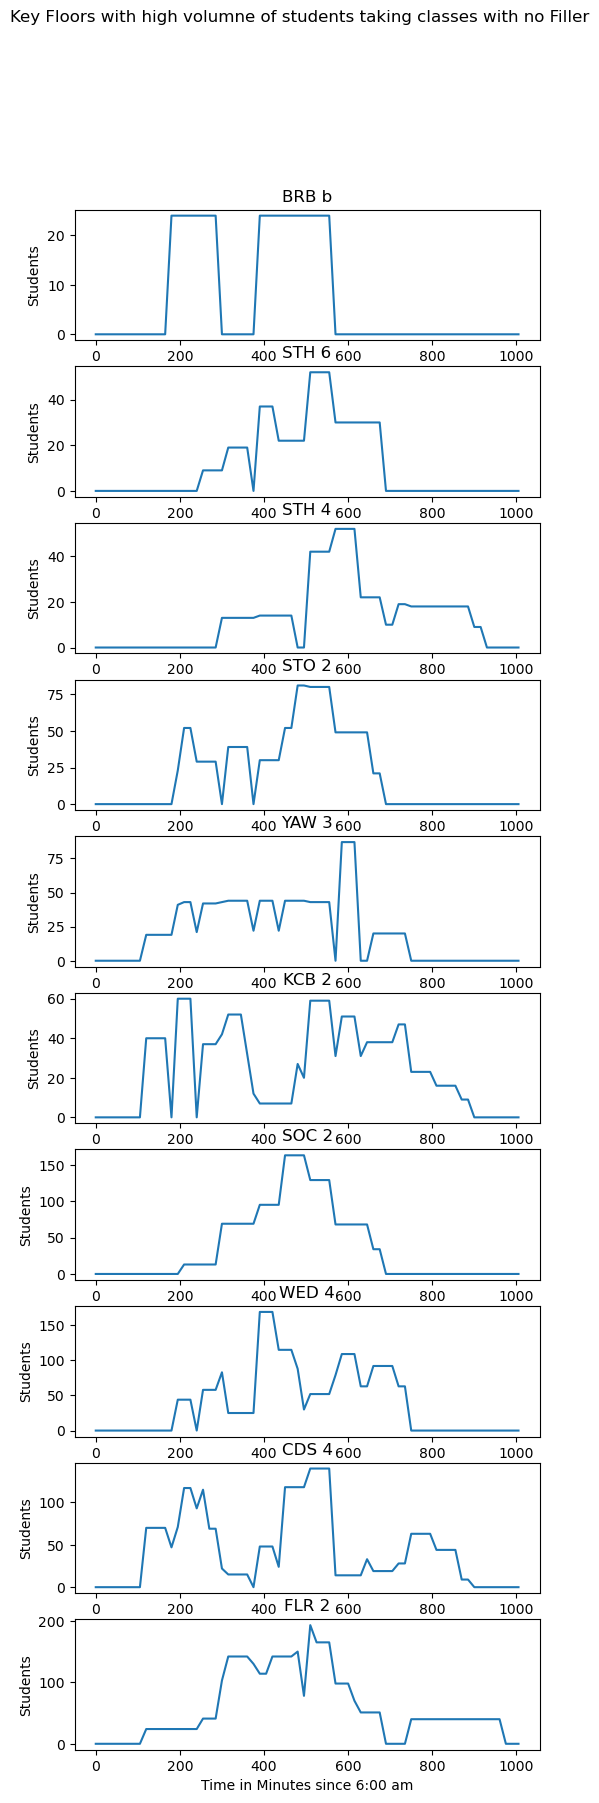

In [98]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(10, 1, figsize=(6, 20))

fig.suptitle("Key Floors with high volumne of students taking classes with no Filler")
for i in range(10):
    y = top_auc[i][2]
    ax[i].plot(t, y)
    ax[i].set_xlabel('Time in Minutes since 6:00 am')
    ax[i].set_ylabel('Students')
    ax[i].set_title(top_auc[i][0])
